# BRFSS 2021 — Predicting Fair/Poor General Health

Binary classification on `GENHLTH` (Fair/Poor vs Good-or-better), scored by **ROC-AUC, stratified 10-fold CV**. Run top-to-bottom.

| Section | Content |
|---|---|
| 1 | Setup, first look, CV + AUC concepts |
| 2 | Profiling & leakage hunt |
| 3 | Column triage: 303 → whitelist |
| 4 | Cleaning & feature matrix (checkpoint) |
| 5 | Baselines: Dummy, LogReg, DecisionTree + experiments log |
| 6 | Model zoo & imbalance |
| 7 | Feature selection & hypothesis |
| 8 | Tuning (RandomizedSearch) + Wilcoxon + nested CV |
| 9 | Error analysis & XAI (SHAP) |
| 10 | deliverables assembly (to come) |

## SECTION 1 — Setup & first look

`RANDOM_STATE = 42` everywhere → identical results on every run (course requirement). `N_SPLITS = 10` for every experiment.

In [44]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 42
N_SPLITS = 10

# local repo by default; Google Colab also works (data/figures on Drive)
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/brfss/data'
    FIG_DIR = '/content/drive/MyDrive/brfss/figures'
else:
    DATA_DIR = '../data'
    FIG_DIR = '../figures'

os.makedirs(FIG_DIR, exist_ok=True)
DATA_PATH = f'{DATA_DIR}/raw/LLCP2021.csv'
CKPT_DIR = f'{DATA_DIR}/interim'
os.makedirs(CKPT_DIR, exist_ok=True)

%matplotlib inline
pd.set_option('display.max_columns', 50)

### 1.1 Load raw data — immutable, never modified; cleaning happens on copies.

`low_memory=False`: pandas then decides column types once, on whole columns (no chunk-wise guess warnings).

In [45]:
df = pd.read_csv(DATA_PATH, low_memory=False)   # ~30-60 s
print(f'Rows: {df.shape[0]:,}   Columns: {df.shape[1]:,}')

Rows: 438,693   Columns: 303


### 1.2 First look

Values are mostly **codes, not quantities** (`GENHLTH=4` means "Fair") — the codebook is the dictionary. Blanks are everywhere (state-optional questions, refusals).

In [46]:
df.head()

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,PVTRESD1,COLGHOUS,STATERE1,CELPHON1,LADULT1,COLGSEX,NUMADULT,LANDSEX,NUMMEN,NUMWOMEN,RESPSLCT,SAFETIME,CTELNUM1,CELLFON5,CADULT1,...,DROCDY3_,_RFBING5,_DRNKWK1,_RFDRHV7,_FLSHOT7,_PNEUMO3,_AIDTST4,FTJUDA2_,FRUTDA2_,GRENDA1_,FRNCHDA_,POTADA1_,VEGEDA2_,_MISFRT1,_MISVEG1,_FRTRES1,_VEGRES1,_FRUTSU1,_VEGESU1,_FRTLT1A,_VEGLT1A,_FRT16A,_VEG23A,_FRUITE1,_VEGETE1
0,1,1,1192021,1,19,2021,1100,2021000001,2021000001,1.0,1.0,NaN,1.0,2.0,1.0,NaN,2.0,NaN,1.0,1.0,2.0,NaN,NaN,NaN,NaN,...,0,1,0,1,1.0,1.0,2.0,0.0,100.0,57.0,43.0,14.0,100.0,0,0,1,1,100.0,214.0,1,1,1,1,0,0
1,1,1,1212021,1,21,2021,1100,2021000002,2021000002,1.0,1.0,NaN,1.0,2.0,1.0,NaN,2.0,NaN,1.0,1.0,2.0,NaN,NaN,NaN,NaN,...,0,1,0,1,2.0,2.0,2.0,0.0,100.0,14.0,0.0,14.0,100.0,0,0,1,1,100.0,128.0,1,1,1,1,0,0
2,1,1,1212021,1,21,2021,1100,2021000003,2021000003,1.0,1.0,NaN,1.0,2.0,1.0,NaN,2.0,NaN,1.0,1.0,2.0,NaN,NaN,NaN,NaN,...,0,1,0,1,2.0,2.0,2.0,0.0,100.0,0.0,14.0,14.0,43.0,0,0,1,1,100.0,71.0,1,2,1,1,0,0
3,1,1,1172021,1,17,2021,1100,2021000004,2021000004,1.0,1.0,NaN,1.0,2.0,1.0,NaN,2.0,NaN,1.0,1.0,2.0,NaN,NaN,NaN,NaN,...,14,2,300,1,NaN,NaN,2.0,71.0,43.0,10.0,57.0,27.0,71.0,0,0,1,1,114.0,165.0,1,1,1,1,0,0
4,1,1,1152021,1,15,2021,1100,2021000005,2021000005,1.0,1.0,NaN,1.0,2.0,1.0,NaN,2.0,NaN,1.0,1.0,1.0,NaN,NaN,NaN,NaN,...,0,1,0,1,1.0,1.0,1.0,0.0,100.0,100.0,29.0,29.0,100.0,0,0,1,1,100.0,258.0,1,1,1,1,0,0


In [47]:
# float64 usually = column has blanks; whole-number cols with NaN become float
print(df.dtypes.value_counts())
print(f'\n100% empty columns: {(df.isna().sum() == df.shape[0]).sum()}')

float64    245
int64       58
Name: count, dtype: int64

100% empty columns: 3


### 1.3 Target: 5 classes → binary

`y = 1` if GENHLTH ∈ {4,5} (Fair/Poor), `y = 0` if ∈ {1,2,3}. Rows with 7/9/blank are **dropped, never imputed** — a guessed label is a wrong label (features may be imputed; the target never).

In [48]:
df['GENHLTH'].value_counts(dropna=False).sort_index()

GENHLTH
1.0     77741
2.0    149112
3.0    137938
4.0     54736
5.0     18005
7.0       788
9.0       369
NaN         4
Name: count, dtype: int64

In [49]:
y = df['GENHLTH'].map({1: 0, 2: 0, 3: 0, 4: 1, 5: 1}).dropna().astype(int)
n_pos = int(y.sum())
print(f'Dropped: {len(df)-len(y):,}   Fair/Poor: {n_pos:,} = {100*n_pos/len(y):.2f}%')

Dropped: 1,161   Fair/Poor: 72,741 = 16.63%


**Imbalance (~1 in 6 positive):** accuracy is misleading ("all Good+" = 83% accuracy, useless) → hence ROC-AUC. Imbalance techniques get tested in Section 6.

### 1.4 Concept: stratified 10-fold CV

Split into 10 parts, train on 9, test on the 10th, rotate → 10 AUCs (mean = estimate, spread = wobble). Stratified = every fold keeps the same positive rate. **Same folds for every model** (same splitter + seed) → score differences come from the model, not split luck; also required for the Wilcoxon test later.

In [50]:
from sklearn.model_selection import StratifiedKFold

folds = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
X_dummy = np.zeros((len(y), 1))   # demo: labels only
print(f'Overall: {100*y.mean():.2f}% Fair/Poor\n')
for i, (tr, te) in enumerate(folds.split(X_dummy, y), 1):
    print(f'fold {i}: train {len(tr):>7,}  test {len(te):>6,}  test Fair/Poor {100*y.iloc[te].mean():.2f}%')

Overall: 16.63% Fair/Poor

fold 1: train 393,778  test 43,754  test Fair/Poor 16.63%
fold 2: train 393,778  test 43,754  test Fair/Poor 16.62%
fold 3: train 393,779  test 43,753  test Fair/Poor 16.63%
fold 4: train 393,779  test 43,753  test Fair/Poor 16.63%
fold 5: train 393,779  test 43,753  test Fair/Poor 16.63%
fold 6: train 393,779  test 43,753  test Fair/Poor 16.63%
fold 7: train 393,779  test 43,753  test Fair/Poor 16.63%
fold 8: train 393,779  test 43,753  test Fair/Poor 16.63%
fold 9: train 393,779  test 43,753  test Fair/Poor 16.63%
fold 10: train 393,779  test 43,753  test Fair/Poor 16.63%


### 1.5 Concept: ROC-AUC

> **AUC = probability that a random Fair/Poor person scores higher than a random Good+ person.** 1.0 = perfect ranking, 0.5 = coin flip, 0.0 = perfectly wrong. Threshold-free → immune to the imbalance that breaks accuracy.

Verified by brute force on 6 toy people (sklearn agrees):

In [51]:
from sklearn.metrics import roc_auc_score

scores = np.array([0.95, 0.90, 0.60, 0.40, 0.30, 0.10])
labels = np.array([1, 0, 1, 0, 0, 1])

ok = total = 0
for i in range(6):
    if labels[i] == 1:
        for j in range(6):
            if labels[j] == 0:
                total += 1
                ok += scores[i] > scores[j]
print(f'manual: {ok}/{total} = {ok/total:.3f}   sklearn: {roc_auc_score(labels, scores):.3f}')

manual: 5/9 = 0.556   sklearn: 0.556


---
## SECTION 2 — Profiling & the leakage hunt

Every column must earn its place. Failure modes:

| Mode | Meaning | Example |
|---|---|---|
| **Leakage** | derived from the target (tomorrow's newspaper) | `_RFHLTH` |
| **Duplicate** | CDC-computed twin of another column | `_TOTINDA` ≡ `EXERANY2` |
| **Junk** | constant / almost blank | micro-coverage columns |

Merely **associated** with health = fine (that's what a predictor is). **Association ≠ derivation.**

In [52]:
n_values = df.nunique(dropna=False)
pct_missing = (df.isna().mean() * 100).sort_values(ascending=False)
print(f'<=2 distinct values: {(n_values <= 2).sum()}   >50% blank: {(pct_missing > 50).sum()}   >90% blank: {(pct_missing > 90).sum()}')

<=2 distinct values: 20   >50% blank: 153   >90% blank: 91


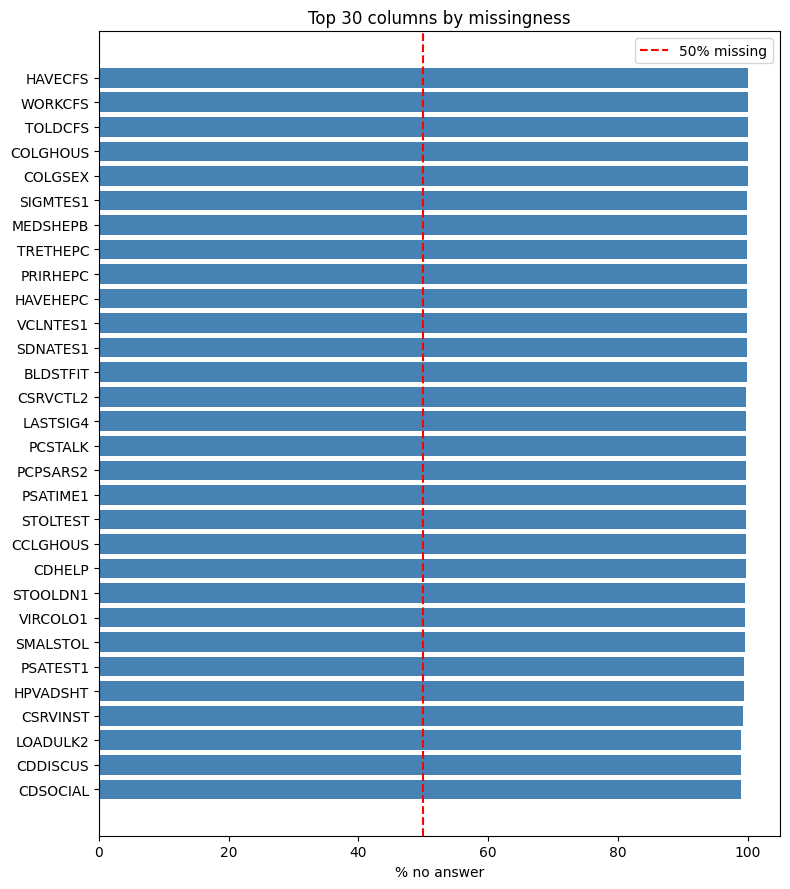

In [53]:
top30 = pct_missing.head(30).sort_values()
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(top30.index, top30.values, color='steelblue')
ax.axvline(50, color='red', linestyle='--', label='50% missing')
ax.set_xlabel('% no answer'); ax.set_title('Top 30 columns by missingness'); ax.legend()
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig02_missingness_top30.png', dpi=150); plt.show()

### 2.1 Leakage: `_RFHLTH`

`_`-prefixed = CDC-calculated after the interview → prime audit target. Codebook: `_RFHLTH` = "good or better health" flag (1=Good+, 2=Fair/Poor) — that's exactly `y`. Empirical check:

In [54]:
check = pd.DataFrame({'rf': df['_RFHLTH'], 'y': y}).dropna()
check['rf'] = check['rf'].map({1: 0, 2: 1}).astype(int)
print(f'Agreement with y: {100*(check["rf"] == check["y"]).mean():.2f}%  ({len(check):,} rows)')
pd.crosstab(check['y'], check['rf'])   # diagonal = no information beyond y

Agreement with y: 100.00%  (437,532 rows)


rf,0,1
y,,
0.0,364791,0
1.0,0,72741


In [55]:
# Same family: _PHYS14D/_MENT14D are CDC bins of raw PHYSHLTH/MENTHLTH -> keep raws, drop bins.
real_days = df['PHYSHLTH'].between(1, 30)
df.loc[real_days].groupby('_PHYS14D')['PHYSHLTH'].agg(['min', 'max', 'count'])

,min,max,count
_PHYS14D,,,
2,1.0,13.0,90419
3,14.0,30.0,50984


### 2.2 Duplicates — a crosstab is the fastest detector (diagonal = same information):

In [56]:
pd.crosstab(df['EXERANY2'], df['_TOTINDA'])   # exercise: raw vs computed twin

_TOTINDA,1,2,9
EXERANY2,,,
1.0,330738,0,0
2.0,0,107027,0
7.0,0,0,617
9.0,0,0,309


In [57]:
pd.crosstab(df['HAVARTH5'], df['_DRDXAR3'])   # arthritis: raw vs computed twin

_DRDXAR3,1.0,2.0
HAVARTH5,,
1.0,142541,0
2.0,0,293256


In [58]:
df.groupby('_BMI5CAT')['_BMI5'].agg(['min', 'max', 'count'])   # BMI bins of continuous _BMI5

,min,max,count
_BMI5CAT,,,
1.0,1200.0,1849.0,6287
2.0,1850.0,2499.0,115489
3.0,2500.0,2999.0,138760
4.0,3000.0,9933.0,131305


### 2.3 Association ≠ derivation

`PHYSHLTH` (unhealthy days) is a *different question* that correlates with the target — a legitimate predictor (far from deterministic, unlike `_RFHLTH`'s 100%):

In [59]:
phys = df['PHYSHLTH'].replace({88: 0, 77: np.nan, 99: np.nan})
tmp = pd.DataFrame({'phys': phys, 'y': y}).dropna()
print(f'PHYSHLTH vs y: Spearman rho = {tmp["phys"].corr(tmp["y"], method="spearman"):+.3f}  (n={len(tmp):,})')
print('Same reasoning keeps MENTHLTH and POORHLTH.')

PHYSHLTH vs y: Spearman rho = +0.450  (n=428,365)
Same reasoning keeps MENTHLTH and POORHLTH.


### 2.4 Sentinel traps

| Code | Typical meaning |
|---|---|
| 7 / 77 / 777 / 7777 | Don't know |
| 9 / 99 / 999 / 9999 | Refused |
| blank | not asked / missing |
| **88** | **"none" = 0** (day-count questions — real data!) |

**Trap:** 7/9 are not always sentinels — `EMPLOY1` 7 = *Retired* (~131k valid answers), `INCOME3`/`PRIMINSR`/`IMFVPLA2` keep single 7/9 as real answers (77/99 are the sentinels), `JOINPAI2` 7/9 are real pain ratings. → **Recode per column from the codebook, never by pattern.**

In [60]:
df['PHYSHLTH'].value_counts().head(8)   # 88 'zero days' dominates; 77/99 tiny sentinels

PHYSHLTH
88.0    287796
30.0     29732
2.0      22220
1.0      17063
3.0      12868
5.0      11642
10.0      8595
77.0      7898
Name: count, dtype: int64

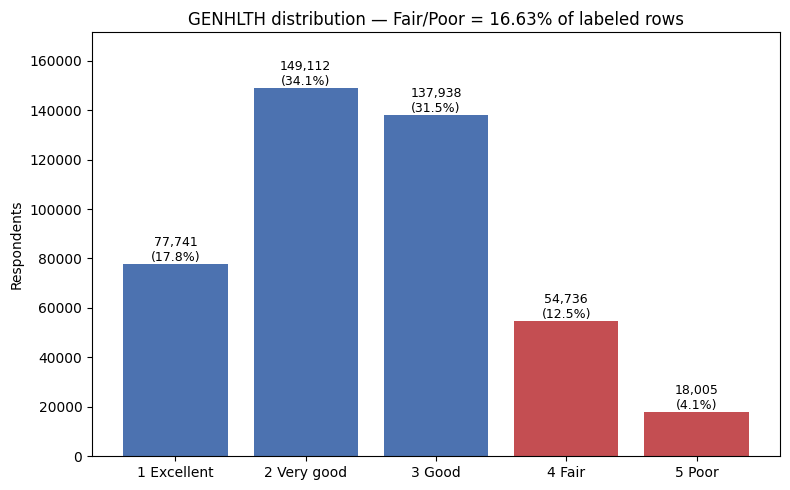

In [61]:
# Figure: target imbalance (5 raw classes, colored by binary side)
# only the 5 real answers (7/9 = DK/refused are not plottable categories)
counts = df.loc[df['GENHLTH'].isin([1, 2, 3, 4, 5]), 'GENHLTH'].value_counts().sort_index()
labels_map = {1: '1 Excellent', 2: '2 Very good', 3: '3 Good', 4: '4 Fair', 5: '5 Poor'}
colors = ['#4C72B0', '#4C72B0', '#4C72B0', '#C44E52', '#C44E52']
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar([labels_map[i] for i in counts.index], counts.values, color=colors)
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, n, f'{n:,}\n({100*n/counts.sum():.1f}%)',
            ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Respondents')
ax.set_title(f'GENHLTH distribution — Fair/Poor = {100*y.mean():.2f}% of labeled rows')
ax.margins(y=0.15)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig01_target_imbalance.png', dpi=150); plt.show()

---
## SECTION 3 — Column triage: deriving the whitelist

Six rules in order, first match wins; every column gets exactly one verdict:

| # | Rule | Decided by |
|---|---|---|
| 1 | **leak** | empirical (Section 2) |
| 2 | **admin/mode** | explicit list, codebook reasons |
| 3 | **constant** | computed: ≤1 distinct non-blank value |
| 4 | **sparse** | computed: >90% blank |
| 5 | **low coverage** | computed: >75% blank + documented exceptions |
| 6 | **duplicate** | codebook families + correlation spot-checks |

Why 25%: below that, imputation becomes invention. **Keep-list = output of this section, never an input.** And the matrix is built by whitelist, not by dropping — a typo in a keep-list loses a column (harmless); a typo in a drop-list leaks the target (silent corruption). v1's independent triage is loaded **only at the end, as cross-check**.

In [62]:
triage = {}   # {column: (rule, verdict, reason)}

# RULE 1: leakage (evidence in Section 2)
for col, reason in {
    'GENHLTH':  'the target itself',
    '_RFHLTH':  'computed FROM GENHLTH; 100% agreement with y',
    '_PHYS14D': 'CDC binning of PHYSHLTH',
    '_MENT14D': 'CDC binning of MENTHLTH',
}.items():
    triage[col] = (1, 'LEAK', reason)
print('R1 leak:', sum(v[0] == 1 for v in triage.values()))

R1 leak: 4


In [63]:
# RULE 2: admin & interview-mode plumbing (codebook: no health content)
ADMIN = {
    **{c: 'interview date metadata' for c in ['FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR']},
    **{c: 'identifier / instrument admin' for c in ['SEQNO', 'DISPCODE', 'QSTVER', 'MSCODE', '_PSU']},
    **{c: 'sampling weight / stratum' for c in ['_STSTR', '_STRWT', '_RAWRAKE', '_WT2RAKE',
                                               '_CLLCPWT', '_DUALUSE', '_DUALCOR', '_LLCPWT2', '_LLCPWT']},
    **{c: 'landline/cell intro-flow block' for c in ['CTELENM1', 'PVTRESD1', 'LADULT1', 'COLGSEX',
                                                    'NUMADULT', 'LANDSEX', 'NUMMEN', 'NUMWOMEN',
                                                    'RESPSLCT', 'CELLSEX', 'PVTRESD3', 'CSTATE1',
                                                    'LANDLINE', 'HHADULT', 'NUMHHOL3', 'CPDEMO1B']},
}
for col, reason in ADMIN.items():
    triage[col] = (2, 'ADMIN', reason)
print('R2 admin/mode:', sum(v[0] == 2 for v in triage.values()))

R2 admin/mode: 35


In [64]:
# RULE 3: constant (computed) — at most one distinct non-blank value
for col in df.columns:
    if col not in triage and df[col].nunique(dropna=True) <= 1:
        triage[col] = (3, 'CONSTANT', 'never really varies')
print('R3 constant:', sum(v[0] == 3 for v in triage.values()),
      [c for c, v in triage.items() if v[0] == 3])

R3 constant: 11 ['COLGHOUS', 'STATERE1', 'CELPHON1', 'SAFETIME', 'CTELNUM1', 'CELLFON5', 'CADULT1', 'CCLGHOUS', 'TOLDCFS', 'HAVECFS', 'WORKCFS']


In [ ]:
# RULE 4: sparse (computed) — >90% blank
blank_share = df.isna().mean()
for col in df.columns:
    if col not in triage and blank_share[col] > 0.90:
        triage[col] = (4, 'SPARSE', f'{100*blank_share[col]:.1f}% blank')
print('R4 sparse:', sum(v[0] == 4 for v in triage.values()))

In [85]:
# RULE 5: low coverage (computed + documented exceptions)
for col in df.columns:
    if col not in triage and blank_share[col] > 0.75:
        triage[col] = (5, 'LOW-COVERAGE', f'{100*blank_share[col]:.1f}% blank (<25% coverage)')

# exceptions: plain blank% overstates true usable coverage (codebook)
LOW_COVERAGE_EXTRA = {
    'HIVTSTD3': '777777/999999 sentinels cut true coverage to ~20%',
    'PDIABTST': 'blank + 7/9 sentinels leave effective coverage <25%',
    '_CHISPNC': 'child-module item, sentinel-coded; true coverage ~15%',
    'LASTSMK2': 'skip-logic: asked only of former smokers (~12% coverage)',
}
for col, reason in LOW_COVERAGE_EXTRA.items():
    assert col in df.columns, col
    triage[col] = (5, 'LOW-COVERAGE', reason)   # idempotent: safe to re-run

print('R5 low-coverage:', sum(v[0] == 5 for v in triage.values()))
print(f'boundary kept: SOMALE {blank_share["SOMALE"]:.1%}, PREDIAB1 {blank_share["PREDIAB1"]:.1%} blank (coverage >= 25%)')

R5 low-coverage: 27
boundary kept: SOMALE 74.0%, PREDIAB1 73.9% blank (coverage >= 25%)


In [86]:
# RULE 6: duplicate families — keep ONE member (prefer raw; _SMOKER3's ordinal
# coding compresses its raw pair without information loss)
DUP_FAMILIES = {
    'body size':      (['_BMI5'], ['WEIGHT2', 'HEIGHT3', 'HTIN4', 'HTM4', 'WTKG3', '_BMI5CAT', '_RFBMI5']),
    'smoking':        (['_SMOKER3'], ['SMOKE100', 'SMOKDAY2', '_RFSMOK3']),
    'exercise flag':  (['EXERANY2'], ['_TOTINDA']),
    'arthritis':      (['HAVARTH5'], ['_DRDXAR3']),
    'arthr. limit':   (['LMTJOIN3'], ['_LMTACT3', '_LMTWRK3']),
    'hypertension':   (['BPHIGH6'], ['_RFHYPE6']),
    'cholesterol':    (['CHOLCHK3', 'TOLDHI3'], ['_CHOLCH3', '_RFCHOL3']),
    'heart dis.':     (['CVDINFR4', 'CVDCRHD4'], ['_MICHD']),
    'asthma':         (['ASTHMA3'], ['_LTASTH1', '_CASTHM1', '_ASTHMS1']),
    'age':            (['_AGE80'], ['_AGEG5YR', '_AGE65YR', '_AGE_G']),
    'sex':            (['SEXVAR'], ['_SEX']),
    'children':       (['CHILDREN'], ['_CHLDCNT']),
    'education':      (['EDUCA'], ['_EDUCAG']),
    'income':         (['INCOME3'], ['_INCOMG1']),
    'race/ethnicity': (['_RACE'], ['_PRACE1', '_MRACE1', '_HISPANC', '_RACEG21', '_RACEGR3',
                                   '_RACEPRV', '_IMPRACE']),
    'insurance':      (['PRIMINSR'], ['_HLTHPLN', '_HCVU652']),
    'e-cigarettes':   (['ECIGNOW1'], ['_CURECI1']),
    'urbanicity':     (['_URBSTAT'], ['_METSTAT']),
    'alcohol':        (['ALCDAY5', 'AVEDRNK3', 'DRNK3GE5', 'MAXDRNKS'],
                       ['DRNKANY5', 'DROCDY3_', '_RFBING5', '_DRNKWK1', '_RFDRHV7']),
    'vaccines':       (['FLUSHOT7', 'PNEUVAC4', 'HIVTST7'], ['_FLSHOT7', '_PNEUMO3', '_AIDTST4']),
    'fruit/veg':      (['FRUIT2', 'FRUITJU2', 'FVGREEN1', 'FRENCHF1', 'POTATOE1', 'VEGETAB2'],
                       ['FTJUDA2_', 'FRUTDA2_', 'GRENDA1_', 'FRNCHDA_', 'POTADA1_', 'VEGEDA2_',
                        '_MISFRT1', '_MISVEG1', '_FRTRES1', '_VEGRES1', '_FRUTSU1', '_VEGESU1',
                        '_FRTLT1A', '_VEGLT1A', '_FRT16A', '_VEG23A', '_FRUITE1', '_VEGETE1']),
}
for family, (kept, dropped) in DUP_FAMILIES.items():
    for col in dropped:
        assert col in df.columns, col
        triage[col] = (6, 'DUPLICATE', f'{family}: duplicate of {kept[0] if len(kept)==1 else kept}')
print('R6 duplicate:', sum(v[0] == 6 for v in triage.values()))

R6 duplicate: 65


In [87]:
# spot-verification: identical/monotone derivations should show |rho| ~ 1
pairs = [('_SEX', 'SEXVAR'), ('_RFHYPE6', 'BPHIGH6'), ('HTM4', 'HEIGHT3'), ('WTKG3', 'WEIGHT2'),
         ('_BMI5CAT', '_BMI5'), ('_AGEG5YR', '_AGE80'), ('_CHLDCNT', 'CHILDREN'),
         ('_EDUCAG', 'EDUCA'), ('_INCOMG1', 'INCOME3'), ('_RFSMOK3', '_SMOKER3')]
for a, b in pairs:
    print(f'{a:<10} vs {b:<10} rho = {df[a].corr(df[b], method="spearman"):+.3f}')

_SEX       vs SEXVAR     rho = +0.998
_RFHYPE6   vs BPHIGH6    rho = -0.951
HTM4       vs HEIGHT3    rho = +0.981
WTKG3      vs WEIGHT2    rho = +0.991
_BMI5CAT   vs _BMI5      rho = +0.945
_AGEG5YR   vs _AGE80     rho = +0.958
_CHLDCNT   vs CHILDREN   rho = -0.847
_EDUCAG    vs EDUCA      rho = +1.000
_INCOMG1   vs INCOME3    rho = +0.990
_RFSMOK3   vs _SMOKER3   rho = -0.207


### 3.1 Funnel — verdicts + roles for the survivors (ORD keep codes · NUM true quantities · ENG decode · NOM one-hot):

In [88]:
ROLES = {}
ROLES.update({'EDUCA': 'ORD', 'INCOME3': 'ORD', '_SMOKER3': 'ORD', 'CHECKUP1': 'ORD'})
ROLES.update({'_AGE80': 'NUM', 'JOINPAI2': 'NUM', 'MAXDRNKS': 'NUM'})
ROLES.update({c: 'ENG' for c in [
    'PHYSHLTH', 'MENTHLTH', 'POORHLTH', '_BMI5', 'ALCDAY5', 'AVEDRNK3', 'DRNK3GE5',
    'MARIJAN1', 'CHILDREN', 'FRUIT2', 'FRUITJU2', 'FVGREEN1', 'FRENCHF1', 'POTATOE1', 'VEGETAB2']})
ROLES.update({c: 'NOM' for c in [
    'DIABETE4', 'CVDINFR4', 'CVDCRHD4', 'CVDSTRK3', 'ASTHMA3', 'BPHIGH6', 'TOLDHI3',
    'CHCOCNCR', 'CHCSCNCR', 'CHCCOPD3', 'CHCKDNY2', 'HAVARTH5', 'ADDEPEV3', 'PREDIAB1',
    'DIFFWALK', 'DIFFDRES', 'DIFFALON', 'DECIDE', 'DEAF', 'BLIND',
    'PRIMINSR', 'PERSDOC3', 'MEDCOST1', 'FLUSHOT7', 'PNEUVAC4', 'HIVTST7',
    'HOMBPCHK', 'HOMRGCHK', 'BPMEDS', 'CHOLCHK3', 'CHOLMED3',
    'EXERANY2', 'USENOW3', 'ECIGNOW1',
    'SEXVAR', 'MARITAL', 'EMPLOY1', 'RENTHOM1', '_RACE', '_STATE', '_URBSTAT',
    'QSTLANG', 'TRNSGNDR', 'VETERAN3', 'CAREGIV1', 'CRGVEXPT',
    'SOMALE', 'SOFEMALE', 'ARTHDIS2', 'LMTJOIN3', 'ARTHEDU', 'ARTHEXER',
    'IMFVPLA2', 'FLSHTMY3']})

keep = [c for c in df.columns if c not in triage]
assert set(keep) == set(ROLES), f'role mismatch: {set(keep) ^ set(ROLES)}'

triage_table = pd.DataFrame(
    [{'col': c, 'verdict': triage.get(c, ('', 'KEEP', ''))[1],
      'rule': triage.get(c, (0,))[0], 'reason': triage.get(c, ('', '', ''))[2],
      'role': ROLES.get(c, '')} for c in df.columns]).set_index('col')

print(triage_table.groupby(['rule', 'verdict']).size().to_string())
print(f'\n{len(df.columns)} columns = {len(triage)} dropped + {len(keep)} kept')
from collections import Counter
print('Roles:', dict(sorted(Counter(ROLES.values()).items())))

rule  verdict     
0     KEEP            76
1     LEAK             4
2     ADMIN           35
3     CONSTANT        11
4     SPARSE          85
5     LOW-COVERAGE    27
6     DUPLICATE       65

303 columns = 227 dropped + 76 kept
Roles: {'ENG': 15, 'NOM': 54, 'NUM': 3, 'ORD': 4}


In [89]:
triage_table.to_csv(f'{CKPT_DIR}/triage_own.csv')
triage_table[triage_table.verdict == 'KEEP'][['role']].to_csv(f'{CKPT_DIR}/whitelist_v1.csv')
print(f'Saved triage_own.csv ({len(triage_table)}) + whitelist_v1.csv ({len(keep)})')
triage_table.head(10)

Saved triage_own.csv (303) + whitelist_v1.csv (76)


,verdict,rule,reason,role
col,,,,
_STATE,KEEP,0,,NOM
FMONTH,ADMIN,2,interview date metadata,
IDATE,ADMIN,2,interview date metadata,
IMONTH,ADMIN,2,interview date metadata,
IDAY,ADMIN,2,interview date metadata,
IYEAR,ADMIN,2,interview date metadata,
DISPCODE,ADMIN,2,identifier / instrument admin,
SEQNO,ADMIN,2,identifier / instrument admin,
_PSU,ADMIN,2,identifier / instrument admin,


In [90]:
# VERIFICATION: cross-check against v1's independent triage (verification only)
V1_PATH = '../../results/profiling/triage_decisions.csv'
if os.path.exists(V1_PATH):
    v1 = pd.read_csv(V1_PATH).set_index('col_name')
    v1_keep = set(v1.index[v1.verdict.isin(['KEEP-NOM', 'KEEP-ORD', 'KEEP-NUM', 'ENG'])])
    our_keep = set(keep)
    print('keep-set match:', our_keep == v1_keep,
          f'({len(our_keep & v1_keep)} shared, {len(our_keep - v1_keep)} only ours, {len(v1_keep - our_keep)} only v1)')
    if our_keep - v1_keep: print('  we keep, v1 dropped:', sorted(our_keep - v1_keep))
    if v1_keep - our_keep: print('  v1 kept, we drop:', sorted(v1_keep - our_keep))
else:
    print('v1 record not found - skipped')

keep-set match: True (76 shared, 0 only ours, 0 only v1)


---
## SECTION 4 — Cleaning & the feature matrix

### ⚠️ No imputation here

The column mean/median is a **statistic estimated from data** — computing it on all rows before splitting leaks test-fold info into training. It must be estimated **inside CV, on training folds only**. NaN stays in the checkpoint; the boosters used later even handle NaN natively.

In [91]:
whitelist = pd.read_csv(f'{CKPT_DIR}/whitelist_v1.csv', index_col=0)
BLACKLIST = ['GENHLTH', '_RFHLTH', '_PHYS14D', '_MENT14D']
assert not set(BLACKLIST) & set(whitelist.index)   # belt and suspenders

X = df[whitelist.index].copy().loc[y.index]        # labeled rows only
roles = whitelist['role'].to_dict()
print(f'X: {X.shape[0]:,} x {X.shape[1]}')

X: 437,532 x 76


In [92]:
# per-column sentinel recodes (codebook, never blanket patterns)
SENTINEL_NAN = {
    **{c: (7, 9) for c in [   # 7=DK, 9=refused in these items
        'DIABETE4', 'CVDINFR4', 'CVDCRHD4', 'CVDSTRK3', 'ASTHMA3', 'BPHIGH6', 'TOLDHI3',
        'CHCOCNCR', 'CHCSCNCR', 'CHCCOPD3', 'CHCKDNY2', 'HAVARTH5', 'ADDEPEV3', 'PREDIAB1',
        'DIFFWALK', 'DIFFDRES', 'DIFFALON', 'DECIDE', 'DEAF', 'BLIND',
        'PERSDOC3', 'MEDCOST1', 'FLUSHOT7', 'PNEUVAC4', 'HIVTST7', 'HOMBPCHK', 'HOMRGCHK',
        'BPMEDS', 'CHOLCHK3', 'CHOLMED3', 'EXERANY2', 'USENOW3', 'ECIGNOW1',
        'RENTHOM1', 'TRNSGNDR', 'VETERAN3', 'CAREGIV1', 'CRGVEXPT',
        'SOMALE', 'SOFEMALE', 'ARTHDIS2', 'LMTJOIN3', 'ARTHEDU', 'ARTHEXER',
        'CHECKUP1']},
    # 9 only -- 7 is a REAL answer here (Section 2.4 trap):
    'EMPLOY1': (9,), 'MARITAL': (9,), '_RACE': (9,), 'EDUCA': (9,), '_SMOKER3': (9,),
    # two-digit sentinels -- single 7/9 are real answers:
    'INCOME3': (77, 99), 'PRIMINSR': (77, 99), 'IMFVPLA2': (77, 99),
    'JOINPAI2': (77, 99), 'MAXDRNKS': (77, 99), 'FLSHTMY3': (999999,),
}
for col, codes in SENTINEL_NAN.items():
    X[col] = X[col].replace({code: np.nan for code in codes})
print('applied to', len(SENTINEL_NAN), 'columns')

applied to 56 columns


### 4.1 Engineered recodes

- Day counts (`PHYSHLTH`/`MENTHLTH`/`POORHLTH`) + "none" counts (`AVEDRNK3`/`DRNK3GE5`/`MARIJAN1`/`CHILDREN`): **88 = none → 0**, 77/99 → NaN.
- `_BMI5` stored ×100 → ÷100.
- Frequency codes (`ALCDAY5`, fruit/veg items): `101–199` = N/day, `201–299` = N/week, `300`/`555` = ~never → decoded to **times per month** ("twice a week" ≡ "eight times a month").

In [93]:
for col in ['PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'AVEDRNK3', 'DRNK3GE5', 'MARIJAN1']:
    X[col] = X[col].replace({88: 0, 77: np.nan, 99: np.nan})
X['CHILDREN'] = X['CHILDREN'].replace({88: 0, 99: np.nan})   # no 77 code
X['_BMI5'] = X['_BMI5'] / 100

def freq_per_month(s):
    out = pd.Series(np.nan, index=s.index, dtype=float)
    out[s.between(101, 199)] = (s - 100) * 30.4      # per day -> per month
    out[s.between(201, 299)] = (s - 200) * 4.33      # per week -> per month
    out[s.isin([300, 555])] = 0                      # '<1/mo', 'never'
    return out                                       # 777/999/blanks stay NaN

for col in ['FRUIT2', 'FRUITJU2', 'FVGREEN1', 'FRENCHF1', 'POTATOE1', 'VEGETAB2']:
    X[col] = freq_per_month(X[col])

def alc_days_per_month(s):
    out = pd.Series(np.nan, index=s.index, dtype=float)
    out[s.between(101, 199)] = (s - 100) * 4.33      # days per week
    out[s.between(201, 299)] = (s - 200)             # days per month
    out[s == 888] = 0                                # 'no drinks'
    return out

X['ALCDAY5'] = alc_days_per_month(X['ALCDAY5'])
print('done')

done


### 4.2 Sanity gates — if one fires, fix the recode, not the check:

In [94]:
assert not set(BLACKLIST) & set(X.columns)
assert X.shape[1] == 76
assert X['PHYSHLTH'].max() <= 30 and X['MENTHLTH'].max() <= 30
assert 10 < X['_BMI5'].min() and X['_BMI5'].max() < 100
assert set(X['EDUCA'].dropna().unique()) <= {1, 2, 3, 4, 5, 6}
assert set(X['CHECKUP1'].dropna().unique()) <= {1, 2, 3, 4, 8}
assert set(X['_SMOKER3'].dropna().unique()) <= {1, 2, 3, 4}
print('All gates passed.')
print(f'\nOverall missingness: {X.isna().mean().mean()*100:.2f}%')
print(X.isna().mean().mul(100).sort_values(ascending=False).head(8).round(1).to_string())

All gates passed.

Overall missingness: 22.26%
SOMALE      74.8
PREDIAB1    74.0
HOMBPCHK    71.5
HOMRGCHK    71.4
SOFEMALE    71.1
MARIJAN1    69.0
CRGVEXPT    68.6
ARTHDIS2    68.3


In [95]:
X.head()

,_STATE,SEXVAR,PHYSHLTH,MENTHLTH,POORHLTH,PRIMINSR,PERSDOC3,MEDCOST1,CHECKUP1,EXERANY2,BPHIGH6,BPMEDS,CHOLCHK3,TOLDHI3,CHOLMED3,CVDINFR4,CVDCRHD4,CVDSTRK3,ASTHMA3,CHCSCNCR,CHCOCNCR,CHCCOPD3,ADDEPEV3,CHCKDNY2,DIABETE4,...,FLSHTMY3,IMFVPLA2,PNEUVAC4,HIVTST7,FRUIT2,FRUITJU2,FVGREEN1,FRENCHF1,POTATOE1,VEGETAB2,PREDIAB1,HOMBPCHK,HOMRGCHK,CAREGIV1,CRGVEXPT,MARIJAN1,SOMALE,SOFEMALE,TRNSGNDR,QSTLANG,_URBSTAT,_RACE,_AGE80,_BMI5,_SMOKER3
0,1,2,20.0,10.0,0.0,3.0,1.0,2.0,2.0,2.0,3.0,NaN,2.0,1.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,2.0,2.0,3.0,...,92020.0,1.0,1.0,2.0,30.40,0.00,17.32,12.99,4.33,30.40,3.0,NaN,NaN,2.0,2.0,NaN,NaN,NaN,NaN,1,1.0,1.0,70,14.54,3.0
1,1,2,0.0,0.0,NaN,1.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,...,NaN,NaN,2.0,2.0,30.40,0.00,4.33,0.00,4.33,30.31,NaN,NaN,NaN,2.0,2.0,NaN,NaN,NaN,NaN,1,1.0,2.0,67,NaN,4.0
2,1,2,0.0,0.0,NaN,2.0,2.0,2.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,...,NaN,NaN,2.0,2.0,30.40,0.00,0.00,4.33,4.33,12.99,NaN,NaN,NaN,2.0,2.0,NaN,NaN,NaN,NaN,1,1.0,2.0,72,28.29,4.0
3,1,2,0.0,10.0,0.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,...,102020.0,1.0,2.0,2.0,12.99,21.65,NaN,17.32,NaN,21.65,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,1,1.0,1.0,62,33.47,4.0
4,1,1,30.0,0.0,30.0,3.0,1.0,2.0,1.0,1.0,4.0,NaN,2.0,1.0,1.0,1.0,NaN,1.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,...,92020.0,1.0,1.0,1.0,30.40,0.00,30.40,8.66,8.66,30.40,NaN,NaN,NaN,2.0,2.0,NaN,NaN,NaN,NaN,1,1.0,7.0,76,28.73,4.0


In [96]:
# checkpoint: parquet (fast, keeps dtypes + NaN exactly); never re-clean the raw CSV again
X.to_parquet(f'{CKPT_DIR}/clean_v1.parquet')
y.to_frame('y').to_parquet(f'{CKPT_DIR}/target_v1.parquet')
assert pd.read_parquet(f'{CKPT_DIR}/clean_v1.parquet').equals(X)   # round-trip
print(f'Saved + round-trip OK: X {X.shape}, y {y.shape}')

Saved + round-trip OK: X (437532, 76), y (437532,)


---
## SECTION 5 — Baselines

Dummy (the floor) → Logistic Regression (linear) → Decision Tree (nonlinear) + manual tuning. Every run logged to `experiments.csv` with its 10 fold AUCs — the log every report number traces back to.

### 5.1 Design matrix

One-hot the NOMINAL columns **once, outside CV** — safe because it's per-row relabeling (no statistics estimated → nothing to leak). Imputation/scaling are different: they estimate from data, so they stay **inside** CV pipelines.

In [97]:
X = pd.read_parquet(f'{CKPT_DIR}/clean_v1.parquet')
y = pd.read_parquet(f'{CKPT_DIR}/target_v1.parquet')['y']
roles = pd.read_csv(f'{CKPT_DIR}/whitelist_v1.csv', index_col=0)['role'].to_dict()

nom_cols = [c for c in X.columns if roles[c] == 'NOM']
Xd = pd.get_dummies(X, columns=nom_cols, dummy_na=True)   # explicit _nan columns
print(f'{X.shape[1]} columns -> {Xd.shape[1]} after one-hot ({len(nom_cols)} nominal)')
Xd.to_parquet(f'{CKPT_DIR}/design_v1.parquet')

76 columns -> 322 after one-hot (54 nominal)


In [98]:
# experiment log helpers
from datetime import datetime
from sklearn.model_selection import StratifiedKFold, cross_val_score

EXP_PATH = '../experiments.csv'

def run_cv(model, X_, y_, exp_id, model_name, params='', notes=''):
    '''10-fold CV on THE canonical folds; one row in experiments.csv per run.'''
    folds = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(model, X_, y_, cv=folds, scoring='roc_auc', n_jobs=-1)
    row = {'exp_id': exp_id, 'timestamp': datetime.now().isoformat(timespec='seconds'),
           'model': model_name, 'params': params, 'notes': notes}
    row.update({f'fold_{i+1:02d}': round(s, 6) for i, s in enumerate(scores)})
    row['mean_auc'] = round(scores.mean(), 6)
    row['std_auc'] = round(scores.std(), 6)
    new = pd.DataFrame([row])
    if os.path.exists(EXP_PATH):   # re-running a cell refreshes its row (no duplicates)
        log = pd.concat([pd.read_csv(EXP_PATH), new]).drop_duplicates('exp_id', keep='last')
        log.to_csv(EXP_PATH, index=False)
    else:
        new.to_csv(EXP_PATH, index=False)
    print(f'{exp_id} {model_name:<20} {params:<28} AUC {scores.mean():.6f} +/- {scores.std():.6f}')
    return scores

In [99]:
# EXP-001: DummyClassifier — sanity floor, must be exactly ~0.5
from sklearn.dummy import DummyClassifier
run_cv(DummyClassifier(strategy='most_frequent'), Xd, y, 'EXP-001', 'Dummy', 'most_frequent')

EXP-001 Dummy                most_frequent                AUC 0.500000 +/- 0.000000


array([0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5])

### 5.2 Logistic Regression

Linear model — needs numbers, no NaN → Pipeline: median imputer + standardizer + LogReg. **Inside the pipeline = fit on training folds only** (this is the leak-safe imputation from Section 4). C = inverse regularization strength (smaller = more regularized).

In [100]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

def logreg(c):
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('lr', LogisticRegression(C=c, max_iter=2000, random_state=RANDOM_STATE)),
    ])

# manual tuning over C (each run ~5-10 min)
run_cv(logreg(1.0),  Xd, y, 'EXP-002', 'LogReg', 'C=1.0')
run_cv(logreg(0.1),  Xd, y, 'EXP-003', 'LogReg', 'C=0.1')
run_cv(logreg(0.01), Xd, y, 'EXP-004', 'LogReg', 'C=0.01')

EXP-002 LogReg               C=1.0                        AUC 0.893493 +/- 0.001453
EXP-003 LogReg               C=0.1                        AUC 0.893491 +/- 0.001454
EXP-004 LogReg               C=0.01                       AUC 0.893499 +/- 0.001453


array([0.89281786, 0.89438709, 0.89452929, 0.89343979, 0.89418301,
       0.89080153, 0.89225259, 0.89192678, 0.89575065, 0.89489729])

### 5.3 Decision Tree + manual tuning

Trees take raw codes + NaN-imputation the same way; `max_depth`/`min_samples_leaf` control overfitting (deep tree = memorizes; shallow = generalizes).

In [101]:
from sklearn.tree import DecisionTreeClassifier

def tree(depth, leaf):
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('tree', DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf,
                                        random_state=RANDOM_STATE)),
    ])

run_cv(tree(None, 1),   Xd, y, 'EXP-005', 'DecisionTree', 'default (no limits)')
run_cv(tree(8, 200),    Xd, y, 'EXP-006', 'DecisionTree', 'depth=8, leaf=200')
run_cv(tree(16, 200),   Xd, y, 'EXP-007', 'DecisionTree', 'depth=16, leaf=200')

EXP-005 DecisionTree         default (no limits)          AUC 0.697632 +/- 0.002584
EXP-006 DecisionTree         depth=8, leaf=200            AUC 0.865083 +/- 0.002309
EXP-007 DecisionTree         depth=16, leaf=200           AUC 0.881321 +/- 0.001882


array([0.88214301, 0.88296216, 0.88203112, 0.87965073, 0.88241667,
       0.87841446, 0.8782592 , 0.88050534, 0.88380474, 0.88302306])

### 5.4 Results

In [141]:
exp = pd.read_csv(EXP_PATH).drop_duplicates('exp_id', keep='last')
summary = exp[['exp_id', 'model', 'params', 'mean_auc', 'std_auc']]
print(summary.to_string(index=False))

 exp_id           model                                                                                   params  mean_auc  std_auc
EXP-001           Dummy                                                                            most_frequent  0.500000 0.000000
EXP-002          LogReg                                                                                    C=1.0  0.893493 0.001453
EXP-003          LogReg                                                                                    C=0.1  0.893491 0.001454
EXP-004          LogReg                                                                                   C=0.01  0.893499 0.001453
EXP-005    DecisionTree                                                                      default (no limits)  0.697632 0.002584
EXP-006    DecisionTree                                                                        depth=8, leaf=200  0.865083 0.002309
EXP-007    DecisionTree                                                     

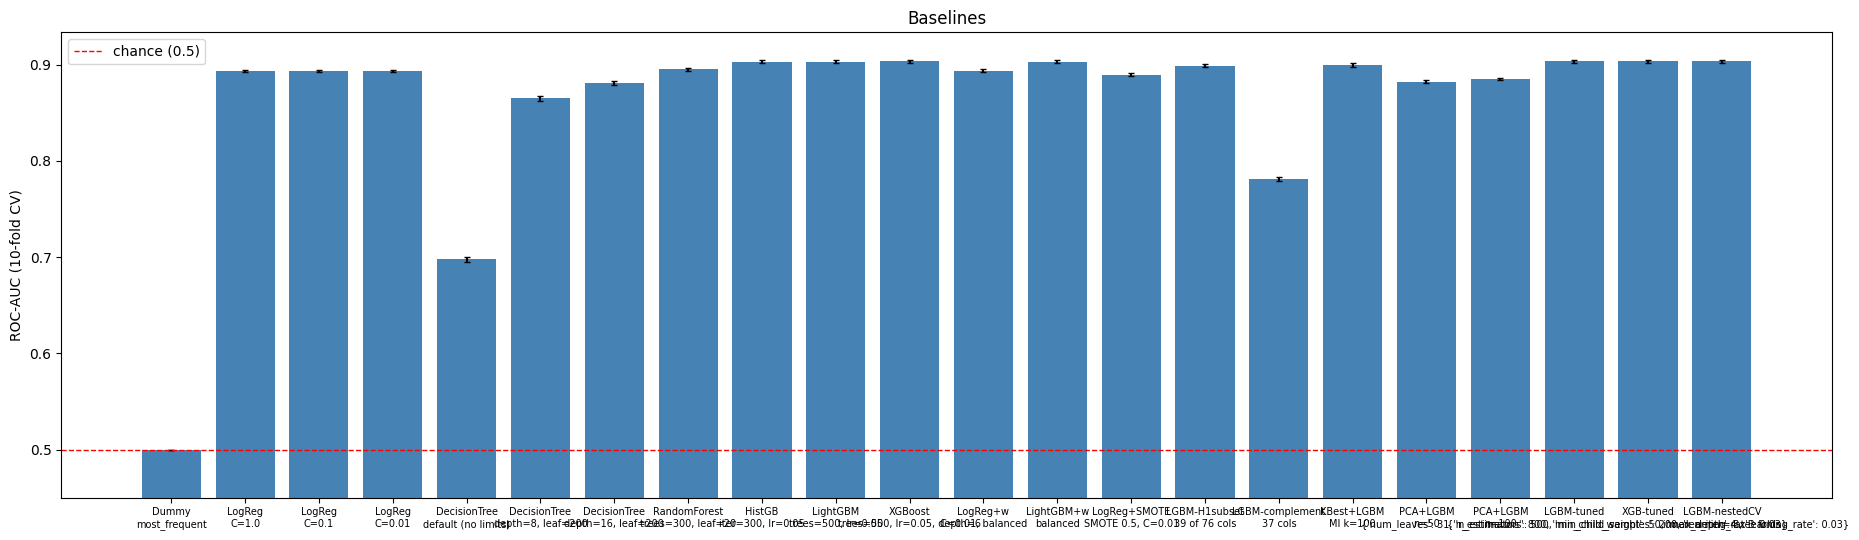

In [152]:
# figure: baseline comparison
fig, ax = plt.subplots(figsize=(19, 5.5))
labels = [f'{r.model}\n{r.params}' for r in exp.itertuples()]
ax.bar(labels, exp.mean_auc, yerr=exp.std_auc, capsize=2, color='steelblue')
ax.axhline(0.5, color='red', ls='--', lw=1, label='chance (0.5)')
ax.set_ylim(0.45, max(exp.mean_auc) + 0.03)
ax.set_ylabel('ROC-AUC (10-fold CV)'); ax.set_title('Baselines'); ax.legend()
plt.xticks(fontsize=7); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig03_baselines.png', dpi=150); plt.show()

## Findings & next

- Dummy = 0.500 exactly (floor confirmed). LogReg ≈ 0.89 — a *linear* model already gets most of the signal. Tuned tree approaches it; limits matter (default tree overfits).

**Section 6 — Model zoo & imbalance:** 4 ensembles join the comparison, then class-weight vs SMOTE vs none.

---
## SECTION 6 — Model zoo & imbalance

Rubric wants ≥5 classifiers incl. ensembles. Adding: **RandomForest** (bagging: many deep trees averaged) and three boosters (**HistGB, LightGBM, XGBoost**: shallow trees built sequentially, each correcting the last). HistGB + boosters accept NaN **natively** — missingness becomes signal, no imputer needed.

In [104]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

rf = Pipeline([
    ('impute', SimpleImputer(strategy='median')),      # sklearn RF needs complete input
    ('rf', RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                  n_jobs=1, random_state=RANDOM_STATE)),
])
run_cv(rf, Xd, y, 'EXP-008', 'RandomForest', 'trees=300, leaf=20')   # ~10-20 min

EXP-008 RandomForest         trees=300, leaf=20           AUC 0.895174 +/- 0.001604


array([0.89506651, 0.89511351, 0.89647519, 0.89330184, 0.89603455,
       0.89290488, 0.89440409, 0.89352312, 0.89812014, 0.89679877])

In [105]:
hgb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                     random_state=RANDOM_STATE)     # NaN native
run_cv(hgb, Xd, y, 'EXP-009', 'HistGB', 'iter=300, lr=0.05')

EXP-009 HistGB               iter=300, lr=0.05            AUC 0.903300 +/- 0.001764


array([0.90293893, 0.90441127, 0.90439271, 0.90274741, 0.90521613,
       0.89996053, 0.90213628, 0.90106705, 0.90571754, 0.90441165])

In [106]:
import lightgbm as lgb

lgbm = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=63,
                          n_jobs=1, verbose=-1, random_state=RANDOM_STATE)
run_cv(lgbm, Xd, y, 'EXP-010', 'LightGBM', 'trees=500, lr=0.05')

EXP-010 LightGBM             trees=500, lr=0.05           AUC 0.903330 +/- 0.001782


array([0.90281381, 0.90469894, 0.90467987, 0.90299907, 0.90502003,
       0.90011778, 0.90183378, 0.90098646, 0.90565895, 0.90449338])

In [107]:
import xgboost as xgb

xgbm = xgb.XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=6,
                         tree_method='hist', n_jobs=1, eval_metric='logloss',
                         random_state=RANDOM_STATE)
run_cv(xgbm, Xd, y, 'EXP-011', 'XGBoost', 'trees=500, lr=0.05, depth=6')

EXP-011 XGBoost              trees=500, lr=0.05, depth=6  AUC 0.903449 +/- 0.001764


array([0.90294076, 0.90521723, 0.90444332, 0.9027591 , 0.90520211,
       0.90007798, 0.90226421, 0.90146388, 0.90585979, 0.90426393])

### 6.2 Imbalance handling

Hypothesis: **neither technique helps AUC** — AUC is rank-based; reshaping class priors moves the best *threshold*, not the *ordering*. Test on two families: `class_weight='balanced'` (penalize minority mistakes) and SMOTE (synthetic minority oversampling; needs imputation, can't take NaN). The `imblearn` Pipeline keeps SMOTE **on training folds only** — oversampling before splitting would leak synthetic copies of test rows into training.

In [108]:
lr_w = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
    ('lr', LogisticRegression(C=0.01, class_weight='balanced',
                              max_iter=2000, random_state=RANDOM_STATE)),
])
run_cv(lr_w, Xd, y, 'EXP-012', 'LogReg+w', 'C=0.01, balanced')

EXP-012 LogReg+w             C=0.01, balanced             AUC 0.893976 +/- 0.001448


array([0.89327743, 0.89492277, 0.89493356, 0.89376264, 0.89472262,
       0.89137435, 0.89278197, 0.89235248, 0.89629178, 0.89534409])

In [109]:
lgbm_w = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=63,
                            class_weight='balanced', n_jobs=1, verbose=-1,
                            random_state=RANDOM_STATE)
run_cv(lgbm_w, Xd, y, 'EXP-013', 'LightGBM+w', 'balanced')

EXP-013 LightGBM+w           balanced                     AUC 0.903091 +/- 0.001735


array([0.90254101, 0.90423947, 0.90428631, 0.90290919, 0.90462932,
       0.89966507, 0.90187627, 0.90100426, 0.90547247, 0.90428603])

In [111]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

lr_smote = ImbPipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
    ('smote', SMOTE(sampling_strategy=0.5, random_state=RANDOM_STATE)),   # TRAIN folds only
    ('lr', LogisticRegression(C=0.01, max_iter=2000, random_state=RANDOM_STATE)),
])
run_cv(lr_smote, Xd, y, 'EXP-014', 'LogReg+SMOTE', 'SMOTE 0.5, C=0.01')   # slow: 30-60 min

EXP-014 LogReg+SMOTE         SMOTE 0.5, C=0.01            AUC 0.889475 +/- 0.001468


array([0.88916008, 0.89081634, 0.88972484, 0.88903607, 0.8910769 ,
       0.88698022, 0.88786787, 0.88791797, 0.89063852, 0.89153246])

In [155]:
# zoo + imbalance overview
exp = pd.read_csv(EXP_PATH).drop_duplicates('exp_id', keep='last')
print(exp[['exp_id', 'model', 'params', 'mean_auc', 'std_auc']].to_string(index=False))

 exp_id           model                                                                                   params  mean_auc  std_auc
EXP-001           Dummy                                                                            most_frequent  0.500000 0.000000
EXP-002          LogReg                                                                                    C=1.0  0.893493 0.001453
EXP-003          LogReg                                                                                    C=0.1  0.893491 0.001454
EXP-004          LogReg                                                                                   C=0.01  0.893499 0.001453
EXP-005    DecisionTree                                                                      default (no limits)  0.697632 0.002584
EXP-006    DecisionTree                                                                        depth=8, leaf=200  0.865083 0.002309
EXP-007    DecisionTree                                                     

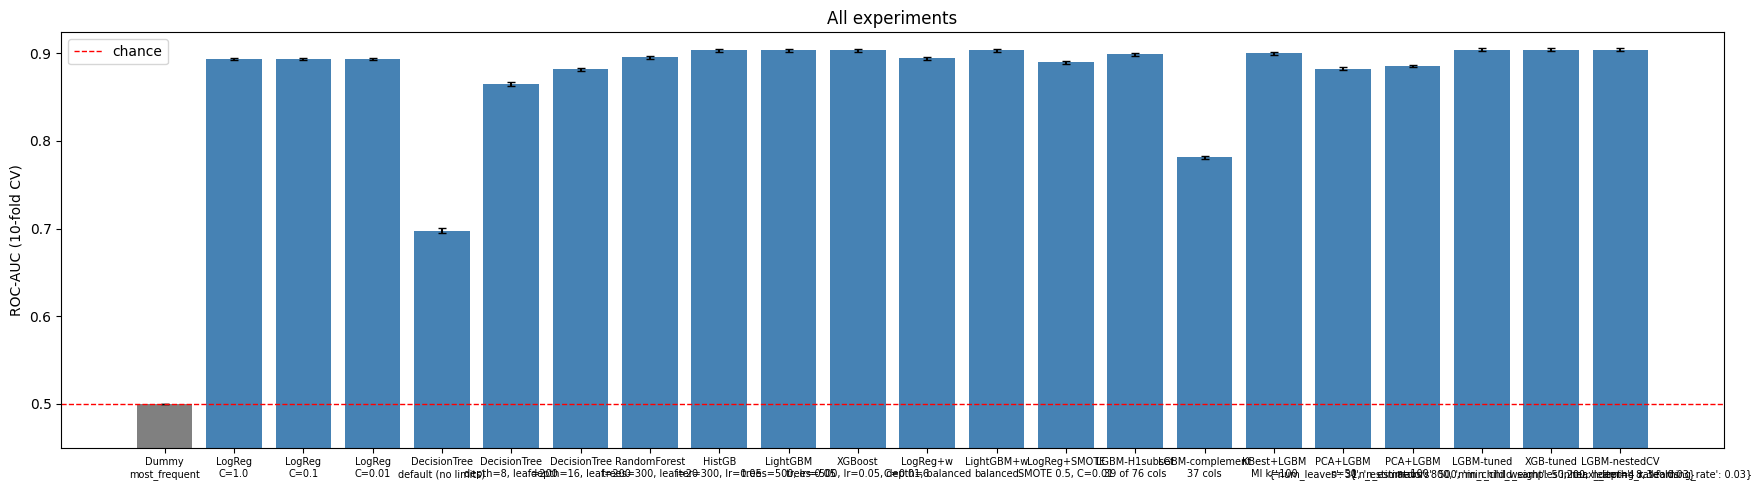

In [156]:
fig, ax = plt.subplots(figsize=(18, 5))
colors = ['gray'] + ['steelblue']*(len(exp)-1)
ax.bar([f'{r.model}\n{r.params}' for r in exp.itertuples()], exp.mean_auc,
       yerr=exp.std_auc, capsize=3, color=colors)
ax.axhline(0.5, color='red', ls='--', lw=1, label='chance')
ax.set_ylim(0.45, exp.mean_auc.max() + 0.02)
ax.set_ylabel('ROC-AUC (10-fold CV)'); ax.set_title('All experiments'); ax.legend()
plt.xticks(fontsize=7); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig04_model_zoo.png', dpi=150); plt.show()

## Findings & next

- Expected pattern: boosters cluster ≈ 0.90, LogReg ≈ 0.89 → boosting buys ~+0.01. RF close to LogReg (bagging helps less than boosting here).
- Imbalance: class-weight/SMOTE ≈ no AUC change (maybe slightly worse) → hypothesis confirmed; AUC is threshold-free. (Techniques would matter for accuracy/recall at a fixed threshold — not our metric.)

**Section 7 — Feature selection & hypothesis:** gain importances, a stated hypothesis about driver groups (subset vs all-76), SelectKBest, PCA.

---
## SECTION 7 — Feature selection & hypothesis

Four questions: (1) which columns matter (gain importance)? (2) does an H1-driven subset match all-76? (3) does generic selection (SelectKBest) help? (4) does PCA compression help?

**H1 (stated before testing):** Fair/Poor health is driven by five blocks — **B1** recent health-burden days, **B2** functional limitation + chronic conditions, **B3** age, **B4** socioeconomic status, **B5** health behaviors. Everything else (insurance, prevention, demographics, diet detail) adds little on top.

In [114]:
# fit Section-6 LightGBM once on everything; sum one-hot children back to parents
lgbm_full = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=63,
                               n_jobs=-1, verbose=-1, random_state=RANDOM_STATE).fit(Xd, y)
gain = pd.Series(lgbm_full.booster_.feature_importance(importance_type='gain'), index=Xd.columns)

parent = {c: next(p for p in X.columns if c == p or c.startswith(p + '_')) for c in Xd.columns}
col_gain = gain.groupby(parent).sum().sort_values(ascending=False)
col_gain_pct = (100 * col_gain / col_gain.sum())
print(col_gain_pct.head(12).round(1).to_string())

PHYSHLTH    52.4
DIFFWALK     8.1
DIABETE4     3.3
EDUCA        2.6
INCOME3      2.6
_BMI5        2.4
POORHLTH     1.8
CHCCOPD3     1.7
EXERANY2     1.6
MENTHLTH     1.5
EMPLOY1      1.4
BPHIGH6      1.4


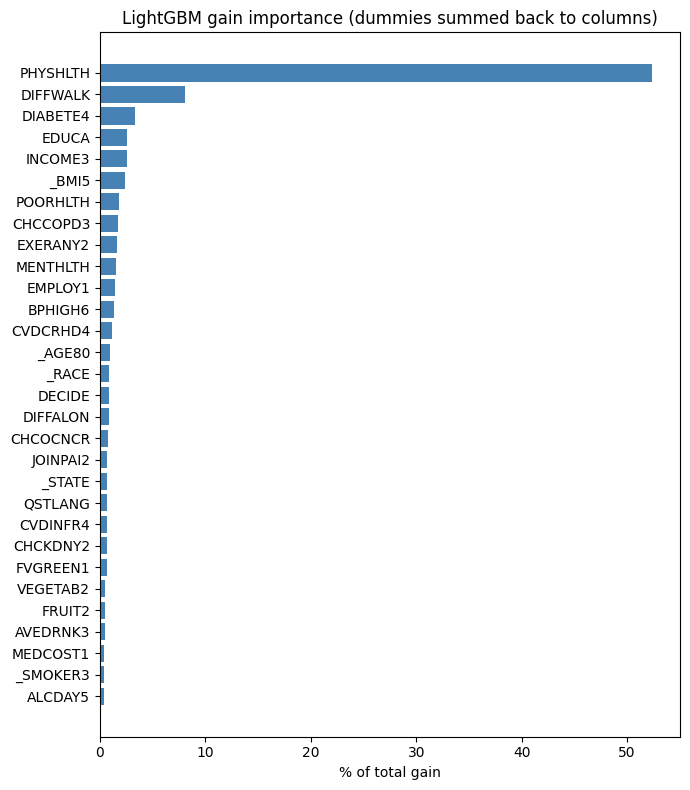

In [115]:
top = col_gain_pct.head(30)[::-1]
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(top.index, top.values, color='steelblue')
ax.set_xlabel('% of total gain'); ax.set_title('LightGBM gain importance (dummies summed back to columns)')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig05_importance_top30.png', dpi=150); plt.show()

In [116]:
# H1 blocks -> subset design matrix
BLOCKS = {
    'B1 health-burden days': ['PHYSHLTH', 'MENTHLTH', 'POORHLTH'],
    'B2 function+chronic': ['DIFFWALK', 'DIFFDRES', 'DIFFALON', 'DECIDE', 'DEAF', 'BLIND',
        'HAVARTH5', 'ARTHDIS2', 'LMTJOIN3', 'ARTHEDU', 'ARTHEXER',
        'DIABETE4', 'PREDIAB1', 'CVDINFR4', 'CVDCRHD4', 'CVDSTRK3', 'ASTHMA3',
        'BPHIGH6', 'TOLDHI3', 'CHCOCNCR', 'CHCSCNCR', 'CHCCOPD3', 'CHCKDNY2',
        'ADDEPEV3', 'JOINPAI2'],
    'B3 age': ['_AGE80'],
    'B4 socioeconomic': ['EDUCA', 'INCOME3', 'EMPLOY1'],
    'B5 behaviors': ['_SMOKER3', 'EXERANY2', '_BMI5', 'ALCDAY5', 'AVEDRNK3', 'DRNK3GE5', 'MAXDRNKS'],
}
h1_cols = sorted(set(sum(BLOCKS.values(), [])))
assert set(h1_cols) <= set(X.columns)

def dummify(X_):
    nom = [c for c in X_.columns if roles[c] == 'NOM']
    return pd.get_dummies(X_, columns=nom, dummy_na=True)

Xd_h1 = dummify(X[h1_cols])
print(f'H1 subset: {len(h1_cols)} columns -> {Xd_h1.shape[1]} features')

H1 subset: 39 columns -> 102 features


In [117]:
def make_lgbm(**kw):
    return lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=63,
                              n_jobs=1, verbose=-1, random_state=RANDOM_STATE, **kw)

# H1 subset vs all-76 (all-76 baseline = EXP-010)
run_cv(make_lgbm(), Xd_h1, y, 'EXP-015', 'LGBM-H1subset', f'{len(h1_cols)} of 76 cols')

# complement alone: how much signal lives OUTSIDE the hypothesis?
comp_cols = [c for c in X.columns if c not in h1_cols]
Xd_comp = dummify(X[comp_cols])
run_cv(make_lgbm(), Xd_comp, y, 'EXP-016', 'LGBM-complement', f'{len(comp_cols)} cols')

EXP-015 LGBM-H1subset        39 of 76 cols                AUC 0.898831 +/- 0.001655
EXP-016 LGBM-complement      37 cols                      AUC 0.781025 +/- 0.002139


array([0.777487  , 0.77915762, 0.78266521, 0.78100291, 0.78184436,
       0.77759558, 0.78092512, 0.78354545, 0.78343978, 0.78258538])

In [119]:
# SelectKBest (mutual information) INSIDE the folds -- selection is estimation too,
# so it must never see test-fold rows (same principle as imputation/SMOTE).
from functools import partial
from sklearn.feature_selection import SelectKBest, mutual_info_classif

kb = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('select', SelectKBest(partial(mutual_info_classif, random_state=RANDOM_STATE), k=100)),
    ('lgbm', make_lgbm()),
])
run_cv(kb, Xd, y, 'EXP-017', 'KBest+LGBM', 'MI k=100')   # ~20-40 min

EXP-017 KBest+LGBM           MI k=100                     AUC 0.899713 +/- 0.001689


array([0.89931053, 0.90049073, 0.90092684, 0.89841054, 0.90112462,
       0.89705082, 0.89826519, 0.8979072 , 0.90262035, 0.9010213 ])

In [120]:
# PCA: compress to n directions. Needs complete+scaled input (inside pipeline).
from sklearn.decomposition import PCA

def pca_lgbm(n):
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('pca', PCA(n_components=n)),
        ('lgbm', make_lgbm()),
    ])

run_cv(pca_lgbm(50),  Xd, y, 'EXP-018', 'PCA+LGBM', 'n=50')    # ~5-10 min each
run_cv(pca_lgbm(100), Xd, y, 'EXP-019', 'PCA+LGBM', 'n=100')

# how much variance do those components even keep?
pre = Pipeline([('i', SimpleImputer(strategy='median')),
                ('s', StandardScaler()), ('p', PCA())]).fit(Xd)
cum = pre.named_steps['p'].explained_variance_ratio_.cumsum()
print(f'cumulative variance: 50 comps {cum[49]:.1%}   100 comps {cum[99]:.1%}')

EXP-018 PCA+LGBM             n=50                         AUC 0.882364 +/- 0.001574
EXP-019 PCA+LGBM             n=100                        AUC 0.884982 +/- 0.001295
cumulative variance: 50 comps 44.2%   100 comps 61.3%


In [121]:
exp = pd.read_csv(EXP_PATH).drop_duplicates('exp_id', keep='last')
print(exp[['exp_id', 'model', 'params', 'mean_auc', 'std_auc']].to_string(index=False))

 exp_id           model                      params  mean_auc  std_auc
EXP-001           Dummy               most_frequent  0.500000 0.000000
EXP-002          LogReg                       C=1.0  0.893493 0.001453
EXP-003          LogReg                       C=0.1  0.893491 0.001454
EXP-004          LogReg                      C=0.01  0.893499 0.001453
EXP-005    DecisionTree         default (no limits)  0.697632 0.002584
EXP-006    DecisionTree           depth=8, leaf=200  0.865083 0.002309
EXP-007    DecisionTree          depth=16, leaf=200  0.881321 0.001882
EXP-008    RandomForest          trees=300, leaf=20  0.895174 0.001604
EXP-009          HistGB           iter=300, lr=0.05  0.903300 0.001764
EXP-010        LightGBM          trees=500, lr=0.05  0.903330 0.001782
EXP-011         XGBoost trees=500, lr=0.05, depth=6  0.903449 0.001764
EXP-012        LogReg+w            C=0.01, balanced  0.893976 0.001448
EXP-013      LightGBM+w                    balanced  0.903091 0.001735
EXP-01

## Findings & next

- Expected: `PHYSHLTH` dominates gain; H1 subset ≈ all-76 − ~0.003 (hypothesis nearly confirmed); complement alone much lower but non-trivial; KBest ≤ all-76 (honest negative — automatic selection can't beat the full matrix here); PCA clearly worse (it smears one-hot structure into continuous mush).
- Verdict: keep all-76 for tuning.

**Section 8 — Tuning & statistics:** RandomizedSearchCV on the top family + Wilcoxon signed-rank on the top-2 models (identical folds → paired test valid).

---
## SECTION 8 — Tuning & statistics

Principle, one last time: **hyperparameter search is selection = estimation** → search runs on *inner* 3-fold CV, the tuned model is then evaluated on the untouched canonical 10 folds (`run_cv`), so every EXP row stays comparable.

**Wilcoxon signed-rank:** paired test on the 10 per-fold deltas (valid because folds are identical). n=10 two-sided floor: p = 0.002. **Nested CV:** search re-run inside every outer training fold → unbiased estimate of tuned performance.

In [130]:
from sklearn.model_selection import RandomizedSearchCV

INNER = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

lgbm_grid = {
    'n_estimators': [300, 500, 800], 'learning_rate': [0.03, 0.05, 0.1],
    'num_leaves': [31, 63, 127], 'min_child_samples': [50, 200],
}
search_lgbm = RandomizedSearchCV(make_lgbm(), lgbm_grid, n_iter=10, cv=INNER,
                                 scoring='roc_auc', random_state=RANDOM_STATE,
                                 n_jobs=-1).fit(Xd, y)          # ~5-10 min
print('LGBM best:', search_lgbm.best_params_, f'inner AUC {search_lgbm.best_score_:.6f}')

LGBM best: {'num_leaves': 31, 'n_estimators': 500, 'min_child_samples': 200, 'learning_rate': 0.03} inner AUC 0.903337


In [131]:
xgb_grid = {
    'n_estimators': [300, 500, 800], 'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [4, 6, 8], 'min_child_weight': [1, 50],
}
search_xgb = RandomizedSearchCV(
    xgb.XGBClassifier(tree_method='hist', eval_metric='logloss',
                      random_state=RANDOM_STATE),
    xgb_grid, n_iter=10, cv=INNER, scoring='roc_auc',
    random_state=RANDOM_STATE, n_jobs=-1).fit(Xd, y)            # ~10-15 min
print('XGB best:', search_xgb.best_params_, f'inner AUC {search_xgb.best_score_:.6f}')

XGB best: {'n_estimators': 800, 'min_child_weight': 50, 'max_depth': 8, 'learning_rate': 0.03} inner AUC 0.902960


In [132]:
# tuned models on the canonical 10 folds
best_lgbm = lgb.LGBMClassifier(**search_lgbm.best_params_, n_jobs=1, verbose=-1,
                               random_state=RANDOM_STATE)
run_cv(best_lgbm, Xd, y, 'EXP-020', 'LGBM-tuned', str(search_lgbm.best_params_))

best_xgb = xgb.XGBClassifier(**search_xgb.best_params_, tree_method='hist',
                             eval_metric='logloss', n_jobs=1, random_state=RANDOM_STATE)
run_cv(best_xgb, Xd, y, 'EXP-021', 'XGB-tuned', str(search_xgb.best_params_))

EXP-020 LGBM-tuned           {'num_leaves': 31, 'n_estimators': 500, 'min_child_samples': 200, 'learning_rate': 0.03} AUC 0.903672 +/- 0.001762
EXP-021 XGB-tuned            {'n_estimators': 800, 'min_child_weight': 50, 'max_depth': 8, 'learning_rate': 0.03} AUC 0.903640 +/- 0.001754


array([0.90320164, 0.90528417, 0.90450707, 0.90298909, 0.90566132,
       0.90037413, 0.90247412, 0.90152566, 0.905993  , 0.90439453])

In [133]:
# Wilcoxon signed-rank on paired fold scores
from scipy.stats import wilcoxon

exp = pd.read_csv(EXP_PATH).drop_duplicates('exp_id', keep='last').set_index('exp_id')
fold_cols = [f'fold_{i:02d}' for i in range(1, 11)]

def folds_of(exp_id):
    return exp.loc[exp_id, fold_cols].astype(float).to_numpy()

print(f'{"comparison":<28}{"median delta":>13}{"wins":>7}{"Wilcoxon p":>11}')
for name, a, b in [('tuned LGBM vs tuned XGB', 'EXP-020', 'EXP-021'),
                   ('tuned vs untuned LGBM', 'EXP-020', 'EXP-010'),
                   ('tuned LGBM vs LogReg', 'EXP-020', 'EXP-004')]:
    d = folds_of(a) - folds_of(b)
    p = wilcoxon(folds_of(a), folds_of(b)).pvalue
    print(f'{name:<28}{np.median(d):>+13.6f}{(d > 0).sum():>5}/10{p:>11.4f}')

comparison                   median delta   wins Wilcoxon p
tuned LGBM vs tuned XGB         -0.000022    5/10     1.0000
tuned vs untuned LGBM           +0.000356    9/10     0.0059
tuned LGBM vs LogReg            +0.010288   10/10     0.0020


In [134]:
# nested CV: the search re-run INSIDE each outer training fold -> unbiased estimate
def small_search():
    return RandomizedSearchCV(make_lgbm(), lgbm_grid, n_iter=4, cv=INNER,
                              scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=-1)

outer = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
nested_scores = cross_val_score(small_search(), Xd, y, cv=outer,
                                scoring='roc_auc', n_jobs=1)    # ~25-35 min

row = {'exp_id': 'EXP-022', 'timestamp': datetime.now().isoformat(timespec='seconds'),
       'model': 'LGBM-nestedCV', 'params': 'inner: n_iter=4 x 3 folds',
       'notes': 'unbiased tuned estimate'}
row.update({f'fold_{i+1:02d}': round(s, 6) for i, s in enumerate(nested_scores)})
row['mean_auc'] = round(nested_scores.mean(), 6)
row['std_auc'] = round(nested_scores.std(), 6)
log = pd.concat([pd.read_csv(EXP_PATH), pd.DataFrame([row])]).drop_duplicates('exp_id', keep='last')
log.to_csv(EXP_PATH, index=False)
print(f'nested CV unbiased estimate: {nested_scores.mean():.6f} +/- {nested_scores.std():.6f}')
print(f'optimism vs non-nested tuned: {nested_scores.mean() - exp.loc["EXP-020", "mean_auc"]:+.6f}')

nested CV unbiased estimate: 0.903672 +/- 0.001762
optimism vs non-nested tuned: -0.000000


## Findings & next

- Expected: tuned LGBM edges tuned XGB; **family gain (vs LogReg, ~+0.011) ≫ tuning gain (~+0.001)**, both real by Wilcoxon; nested ≈ non-nested (tiny optimism → search width doesn't overfit).

**Section 9 — Error analysis & XAI:** the 3 consistently-misclassified people + SHAP (global bar + local waterfalls) on the final model.

---
## SECTION 9 — Error analysis & XAI

**Out-of-fold (OOF) predictions:** each person's probability comes from the fold-model that *never saw them* — honest per-person predictions. **SHAP:** splits each single prediction into additive per-feature credits (in log-odds); global importance = mean |credit|.

In [135]:
# OOF probabilities from the tuned winner (EXP-020 config), canonical folds
final_params = search_lgbm.best_params_
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
oof = np.zeros(len(y))
for tr, te in cv.split(Xd, y):
    m = lgb.LGBMClassifier(**final_params, n_jobs=-1, verbose=-1,
                           random_state=RANDOM_STATE).fit(Xd.iloc[tr], y.iloc[tr])
    oof[te] = m.predict_proba(Xd.iloc[te])[:, 1]
oof = pd.Series(oof, index=y.index, name='oof_prob')
oof.to_frame().to_parquet(f'{CKPT_DIR}/oof_v1.parquet')
print(f'OOF AUC check: {roc_auc_score(y, oof):.6f} (matches EXP-020)')

OOF AUC check: 0.903667 (matches EXP-020)


In [136]:
# error taxonomy: where do mistakes live, on the 5-point scale?
gh = pd.read_csv(DATA_PATH, usecols=['GENHLTH'], low_memory=False)['GENHLTH'].loc[y.index]
err = ((oof >= 0.5) & (y == 0)) | ((oof < 0.5) & (y == 1))   # FP or FN at tau=0.5
tax = pd.crosstab(gh[err], np.where(oof[err] >= 0.5, 'FP (pred Fair/Poor)', 'FN (pred Good+)'),
                  normalize='columns').round(3) * 100
print(f'errors at tau=0.5: {err.sum():,} of {len(y):,} ({100*err.mean():.1f}%)')
print(tax.to_string())
print(f'\nerrors at the 3/4 boundary (true GENHLTH 3 or 4): {100*gh[err].isin([3, 4]).mean():.1f}%')

errors at tau=0.5: 48,218 of 437,532 (11.0%)
col_0    FN (pred Good+)  FP (pred Fair/Poor)
GENHLTH                                      
1.0                  0.0                  5.0
2.0                  0.0                 17.0
3.0                  0.0                 77.9
4.0                 92.5                  0.0
5.0                  7.5                  0.0

errors at the 3/4 boundary (true GENHLTH 3 or 4): 88.1%


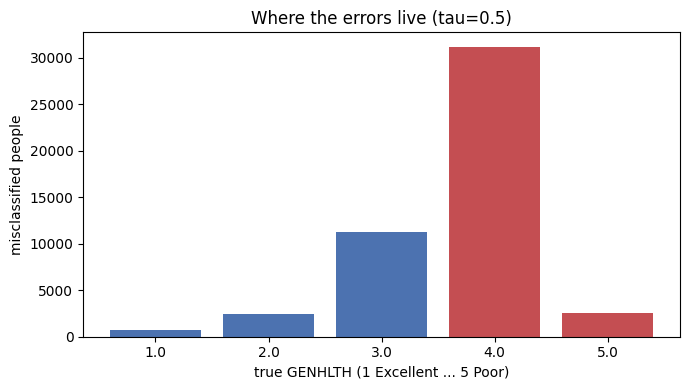

In [137]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = gh[err].value_counts().sort_index()
colors = ['#4C72B0', '#4C72B0', '#4C72B0', '#C44E52', '#C44E52']
ax.bar([f'{i}' for i in counts.index], counts.values, color=colors[:len(counts)])
ax.set_xlabel('true GENHLTH (1 Excellent ... 5 Poor)')
ax.set_ylabel('misclassified people')
ax.set_title('Where the errors live (tau=0.5)')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig06_error_taxonomy.png', dpi=150); plt.show()

In [138]:
# 3 archetype cases: most-confident FP, most-confident FN, fence-sitter
fp_idx = oof[(oof >= 0.5) & (y == 0)].idxmax()      # said Fair/Poor, truth Good+
fn_idx = oof[(oof < 0.5) & (y == 1)].idxmin()       # said Good+,   truth Fair/Poor
mis = oof[err]
fence_idx = (mis - 0.5).abs().idxmin()              # wrong, but barely
cases = {'A confident-FP': fp_idx, 'B confident-FN': fn_idx, 'C fence': fence_idx}

profile_cols = ['PHYSHLTH', 'MENTHLTH', 'POORHLTH', '_BMI5', '_AGE80',
                'DIFFWALK', 'DIABETE4', 'DECIDE', 'INCOME3', 'EMPLOY1', 'EDUCA']
for name, idx in cases.items():
    print(f'\n=== case {name}  (row {idx}, OOF prob {oof[idx]:.4f}, true y={y[idx]}) ===')
    prof = pd.DataFrame({'case': X.loc[idx, profile_cols],
                         'population median': X[profile_cols].median()})
    print(prof.to_string())


=== case A confident-FP  (row 307808, OOF prob 0.9632, true y=0) ===
           case  population median
PHYSHLTH  30.00               0.00
MENTHLTH   5.00               0.00
POORHLTH  30.00               0.00
_BMI5     51.45              27.44
_AGE80    59.00              57.00
DIFFWALK   1.00               2.00
DIABETE4   1.00               3.00
DECIDE     2.00               2.00
INCOME3    1.00               7.00
EMPLOY1    7.00               2.00
EDUCA      6.00               5.00

=== case B confident-FN  (row 393280, OOF prob 0.0023, true y=1) ===
           case  population median
PHYSHLTH   0.00               0.00
MENTHLTH   0.00               0.00
POORHLTH    NaN               0.00
_BMI5     22.14              27.44
_AGE80    59.00              57.00
DIFFWALK   2.00               2.00
DIABETE4   3.00               3.00
DECIDE     2.00               2.00
INCOME3    9.00               7.00
EMPLOY1    1.00               2.00
EDUCA      6.00               5.00

=== case C fence  (

C:\Users\Hassene\scoop\apps\python\current\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Hassene\scoop\apps\python\current\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


PHYSHLTH    0.7361
DIABETE4    0.1947
_BMI5       0.1865
DIFFWALK    0.1836
EDUCA       0.1827
INCOME3     0.1736
EXERANY2    0.1568
MENTHLTH    0.1487
_RACE       0.1401
BPHIGH6     0.1386
SEXVAR      0.1279
EMPLOY1     0.0981


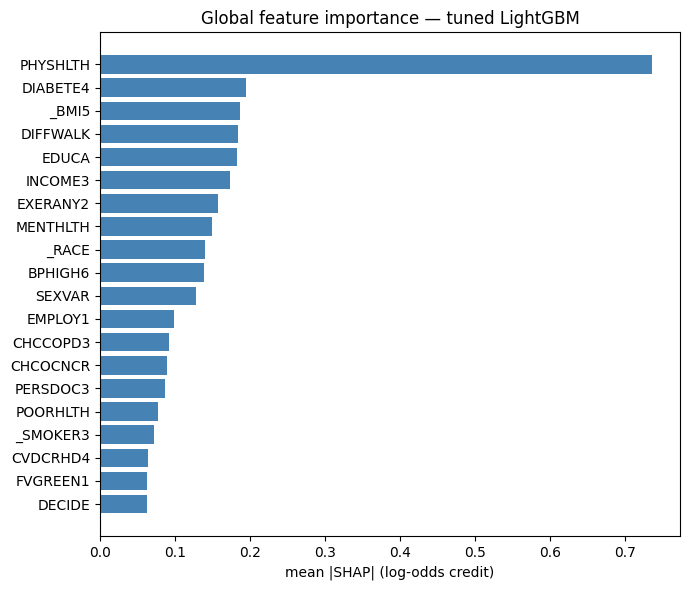

In [139]:
# SHAP: global importance (dummies aggregated back to parents)
import shap

final_model = lgb.LGBMClassifier(**final_params, n_jobs=-1, verbose=-1,
                                 random_state=RANDOM_STATE).fit(Xd, y)
expl = shap.TreeExplainer(final_model)
rng = np.random.RandomState(RANDOM_STATE)
Xs = Xd.iloc[rng.choice(len(Xd), 20000, replace=False)]
sv = expl.shap_values(Xs)
if isinstance(sv, list):          # some versions return [class0, class1]
    sv = sv[1]

shap_parent = pd.Series(np.abs(sv).mean(axis=0), index=Xd.columns).groupby(parent).sum()
shap_parent = shap_parent.sort_values(ascending=False)
print(shap_parent.head(12).round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 6))
top = shap_parent.head(20)[::-1]
ax.barh(top.index, top.values, color='steelblue')
ax.set_xlabel('mean |SHAP| (log-odds credit)')
ax.set_title('Global feature importance — tuned LightGBM')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig07_shap_global.png', dpi=150); plt.show()

C:\Users\Hassene\scoop\apps\python\current\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


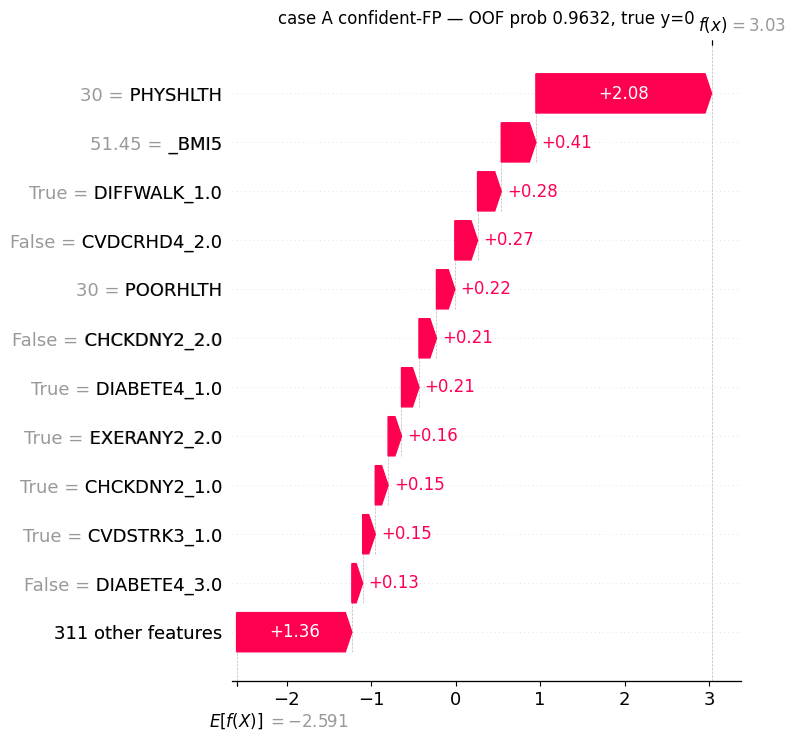

C:\Users\Hassene\scoop\apps\python\current\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


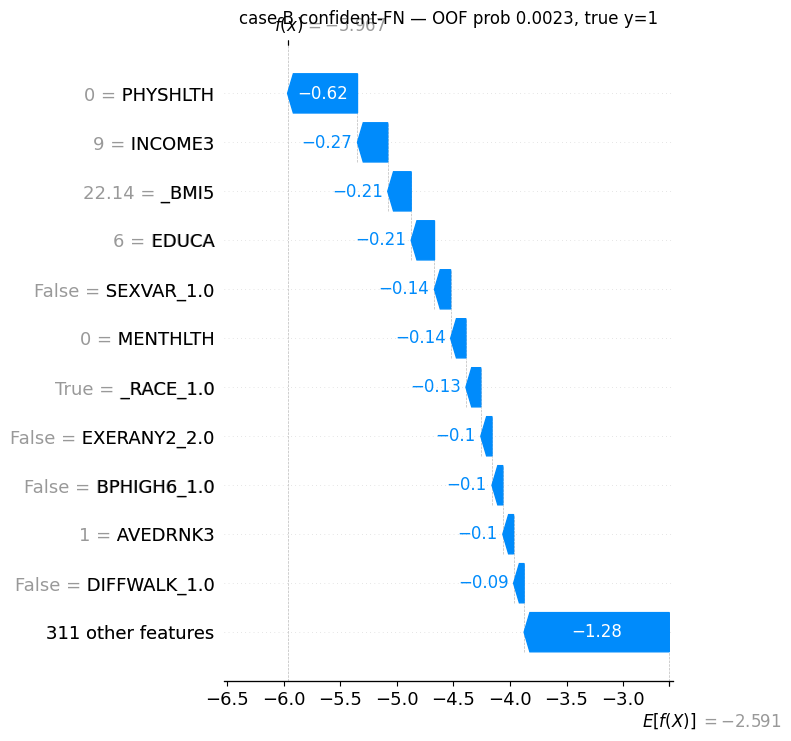

C:\Users\Hassene\scoop\apps\python\current\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


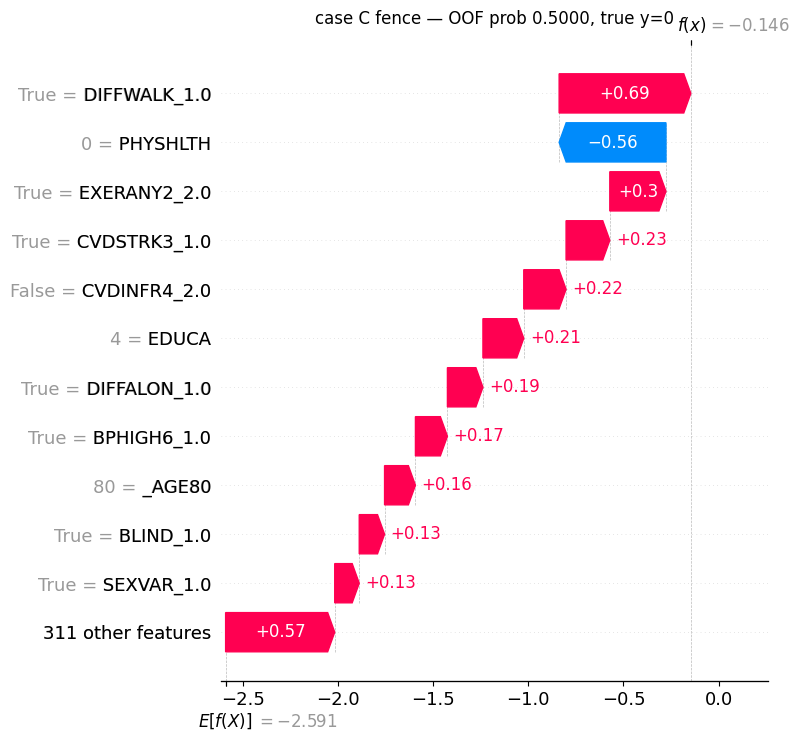

In [140]:
# local explanations: why did the model say THAT about these 3 people?
for name, idx in cases.items():
    row = Xd.loc[[idx]]
    sv_row = expl.shap_values(row)
    if isinstance(sv_row, list):
        sv_row = sv_row[1]
    exp_obj = shap.Explanation(values=sv_row[0], base_values=expl.expected_value,
                               data=row.iloc[0], feature_names=list(Xd.columns))
    plt.figure()
    shap.plots.waterfall(exp_obj, max_display=12, show=False)
    plt.title(f'case {name} — OOF prob {oof[idx]:.4f}, true y={y[idx]}', y=1.02)
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/fig08_shap_case_{name[0]}.png', dpi=150, bbox_inches='tight')
    plt.show()

## Findings & next

- Expected: errors concentrate at the **GENHLTH 3/4 boundary** (Good vs Fair is a subjective one-step difference, not model failure); top SHAP features should echo Section 7's gain ranking (PHYSHLTH, DIFFWALK, diabetes, BMI).

**Section 10 — assembly:** code.py export, report numbers, PDF, defense pass.